# Leaf Classification Exercise Instructions

# Machine Learning and Pattern Recognition (TKO_3120)



This is the template for the image recognition exercise. <Br>
Some **general instructions**:
 - write a clear *report*, understandable for an unspecialized reader: define shortly the concepts and explain the phases you use
    - use the Markdown feature of the notebook for larger explanations
 - return your output as a working Jupyter notebook
 - name your file as MLPR26_exercise_surname_firstname.jpynb
 - write easily readable code with comments     
     - if you exploit some code from web, provide a reference
     - avoid redundant code! Exploit the relevent parts and modify the code for your purposes to produce only what you need
 - it is ok to discuss with a friend about the assignment. But it is not ok to copy someone's work. Everyone should submit their own implementation
 - Use of AI is prohibited

**Deadline 15th of March at 12:00**
- No extension granted, unless you have an extremely justified reason. In such case, ask for extension well in advance!
- Start now, do not leave it to the last minute. This exercise will need some labour!
- If you encounter problems
    - Google first
    - ask for help at the discussion area at Moodle
    - email svwelg@utu.fi

Grading

The exercise covers a part of the grading in this course. The course exam has 5 questions, 6 points of each. Exercise gives 6 points, i.e. the total score is 36 points.

From the template below, you can see how many exercise points can be acquired from each task. Exam points are given according to the table below:

9-10 exercise points: 1 points

11-12 exercise points: 2 points

13-14 exercise points: 3 points

15-16 exercise points: 4 points

17-18 exercise points: 5 points

19-20 exercise points: 6 points

To pass the exercise, you need at least 9 exercise points, distributed somewhat evenly into tasks (you can't just implement Introduction, Data preparation and Feature extraction and leave the left undone!)

# Introduction (1 p)

Write an introductory chapter for your report.

For example:

What is the purpose of this task?

What kind of data are used and where do they originate from?

Which machine learning methods are applied?<br>  
<br>

Dataset

The dataset consists of leaf images from three plant species:

Basil

Lemon

Chinar

Images are from Kaggel.

This project on machine learning and pattern recognition aims to solve a multi-class classification problem. In the scope of the project, 3 different kinds of leaves will be classified, Basil, Chinar and Lemon. To this end, the raw data will be received, they will be prepared for feature extraction (i.e. convert to greyscale, quantization etc.)

# Data Preparation (3 p)

Perform necessary data preparation steps:

Import all required packages in one cell

Read all images from the given folders

Convert images to grayscale when needed

Reduce grayscale quantization (e.g. to 8 gray levels) for texture analysis

Prepare data structures for feature extraction

In [138]:
#Importing Required Packages
import numpy as np
import matplotlib.pyplot as plt
import os
from skimage import io, img_as_float, color
from skimage.feature import graycomatrix, graycoprops

In [139]:
#Reading the Images
DATASET_PATH = os.path.join(".", "Dataset") #The dataset path


#Loads the data and creates a dictionary where keys are labels and values are lists of images
def load_data(datasetPath):
    print(f"Loading data paths:")
    dataPaths = dict()   #Keys are classes, values are lists of paths of images
    for elem in os.listdir(datasetPath):   #Go into each class folder
        path = os.path.join(datasetPath, elem) #Get folder path
        print(f"Walking into {path}")
        imagePaths = []
        for image in os.listdir(path):  #Go into each image path inside class folder
            imagePaths.append(os.path.join(path, image))    #Add image to path list
        dataPaths[elem] = imagePaths #Add list to dictionary
    #Go into directories and get images as actual image objects
    datasets = dict()   
    for label, paths in dataPaths.items():
        datasets[label] = []
        for image in paths:
            img = img_as_float(io.imread(image))
            datasets[label].append(img)
    return datasets

datasets = load_data(DATASET_PATH)

Loading data paths:
Walking into .\Dataset\Basil
Walking into .\Dataset\Chinar
Walking into .\Dataset\Lemon


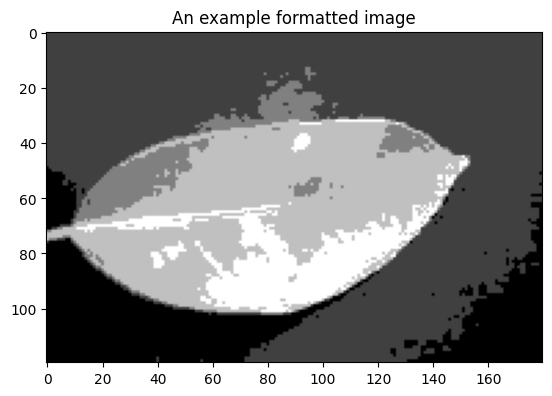

In [140]:
#Formatting the  data
#Converts images to grayscale in the whole dataset
def convertToGray(dataset):
    greyedImgs = dict()
    for label, imgs in dataset.items():
        greyedImgs[label] = list()
        for img in imgs:
            greyedImgs[label].append(color.rgb2gray(img))
    return greyedImgs

#Changes the quantization level of all images in dataset, assumes initial quantization of 256 levels
def changeQuantization(dataset, qLevel):
    for label, data in dataset.items():
        for idx in range(len(data)):
            img = data[idx] #Get original image
            img = np.array(img) #Convert to array
            img = np.floor(img * qLevel).astype(np.uint8)    #Apply new quantization level and convert to integer
            data[idx] = img #Update list
        dataset[label] = data   #Update the key
    return dataset

modifiedDatasets = convertToGray(datasets)  #Convert to greyscale
modifiedDatasets = changeQuantization(modifiedDatasets,8)   #Reduce quantization to 8 gray levels
#Testing to see some images
for label, images in modifiedDatasets.items():
    for img in images:
        plt.imshow(img, cmap='gray')
        plt.title("An example formatted image")

# Feature Extraction

**First order texture measures (6 features)**

Calculate the following color features for each image **(1 p)**:

Mean value of each RGB channel

Variance of each RGB channel<br>
<br>

**Second order texture measures**

Gray-Level Co-Occurrence Matrix (GLCM) features **(2 p)**

For each image:

Convert the image to grayscale

Quantize the grayscale image

Compute GLCM-based texture features

Extract the correlation feature

Explain briefly what the correlation feature measures<br>
<br>


**Additional image-based features**

Extract template-matching features:**(2 p)**

Select one representative template image per class

Compute normalized template matching scores

Use the maximum response as a feature

Explain why template matching may help classification.


### First Order Texture Measures 

In [141]:
#Extracts first level features for a singular image
def getfeaturesDict(img):
    #Get each color channel
    R = img[..., 0]
    G = img[..., 1]
    B = img[..., 2]

    #Get means of each color channel
    meanR = np.mean(R)
    meanG = np.mean(G)
    meanB = np.mean(B)

    #Get variances of each color channel
    varR = np.var(R)
    varG = np.var(G)
    varB = np.var(B)

    return {
        "meanR": meanR,
        "meanG": meanG,
        "meanB": meanB,
        "varR": varR,
        "varG": varG,
        "varB": varB,
    }

#Extracts a single feature and returns as np array
def extractFeature(featureDataset, feature, oneClass = "no"):
    listToStore = list()
    if oneClass != "no":
        images = featureDataset[oneClass]
        for features in images:
            listToStore.append(features[feature])
    else:
        for label, images in featureDataset.items():
            for features in images:
                listToStore.append(features[feature])
    return np.array(listToStore)

#Calculate first order measures for each image
featuresDict = dict()
for label, images in datasets.items():
    temp = list()
    for img in images:
        features = getfeaturesDict(img)
        features["class"] = label   #Add the label to the features as well
        temp.append(features)
    featuresDict[label] = np.array(temp)

### Second Order Texture Measures

In [142]:
distancesGLCM = [1,2,3]
anglesGLCM = [0,45,90]
#Go through the greyscale images and extract their correlation features
for label, images in modifiedDatasets.items():
    temp = list()
    idx  = 0
    for img in images:
        glcm = graycomatrix(image=img,levels=8,distances=distancesGLCM,angles=anglesGLCM,symmetric=True)   #Compute GLCM for 3 distances and 3 angle values
        corr = graycoprops(glcm,prop='correlation')
        featuresDict[label][idx]["correlation"] = corr
        idx += 1

# Feature Relationships

Visualize and analyze the relationships between extracted features.<br>
<br>

**Pairplot (1 p)**

Create a pairplot of the features

Which feature pairs show approximately linear dependence?<br>
<br>

**Histograms (1 p)**

Plot a histogram for each standardized feature

Plot all image classes in the same figure using different colors

Which features seem to have discriminative power?<br>
<br>

**PCA (1 p)**

Perform Principal Component Analysis

Plot the image classes using different colors

Can you see clusters?

What does PCA suggest about classification performance?

Pairplots

Histogram For Mean and Variance

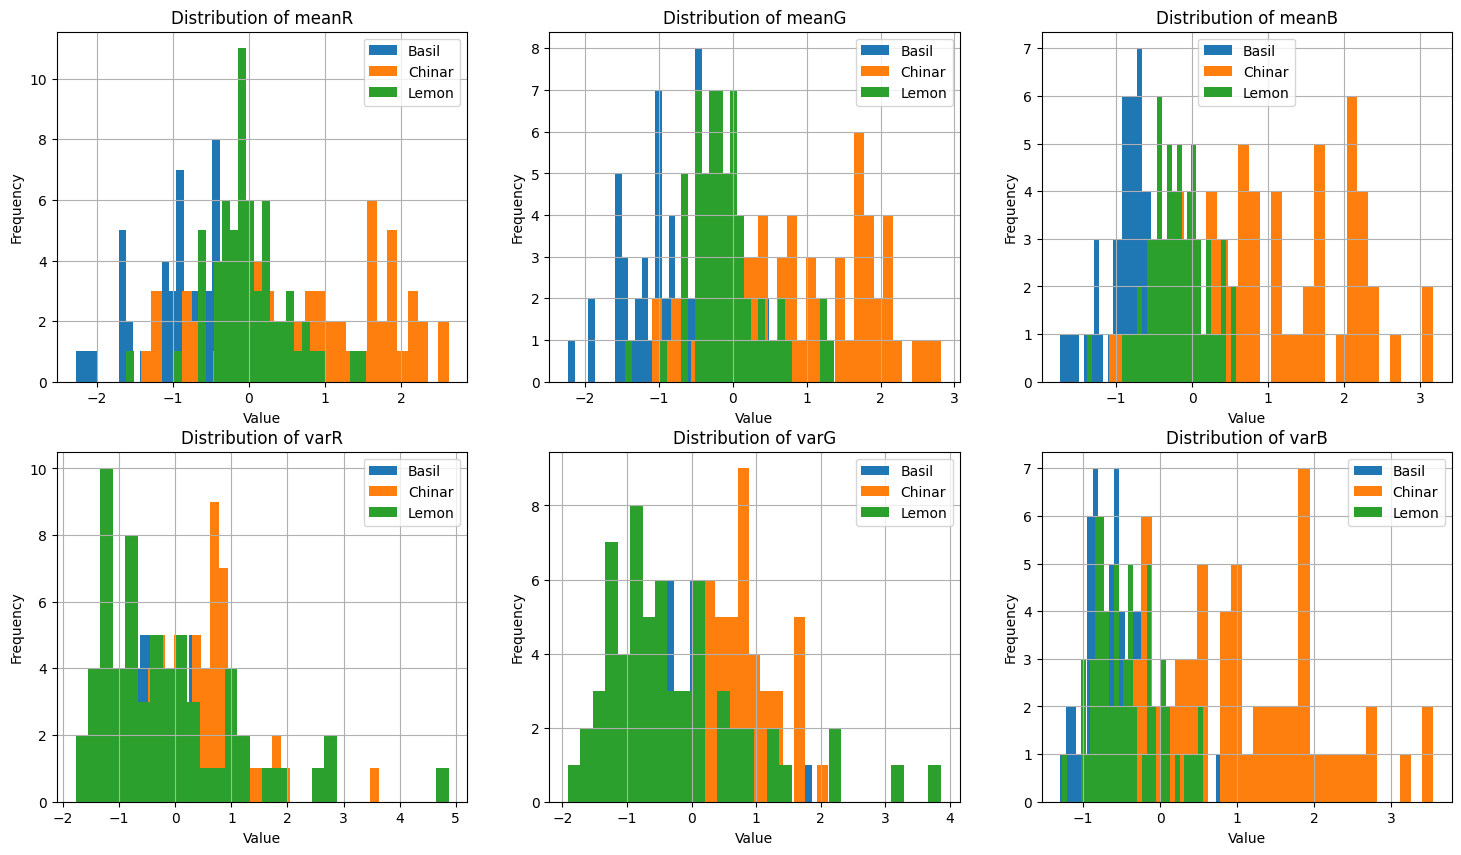

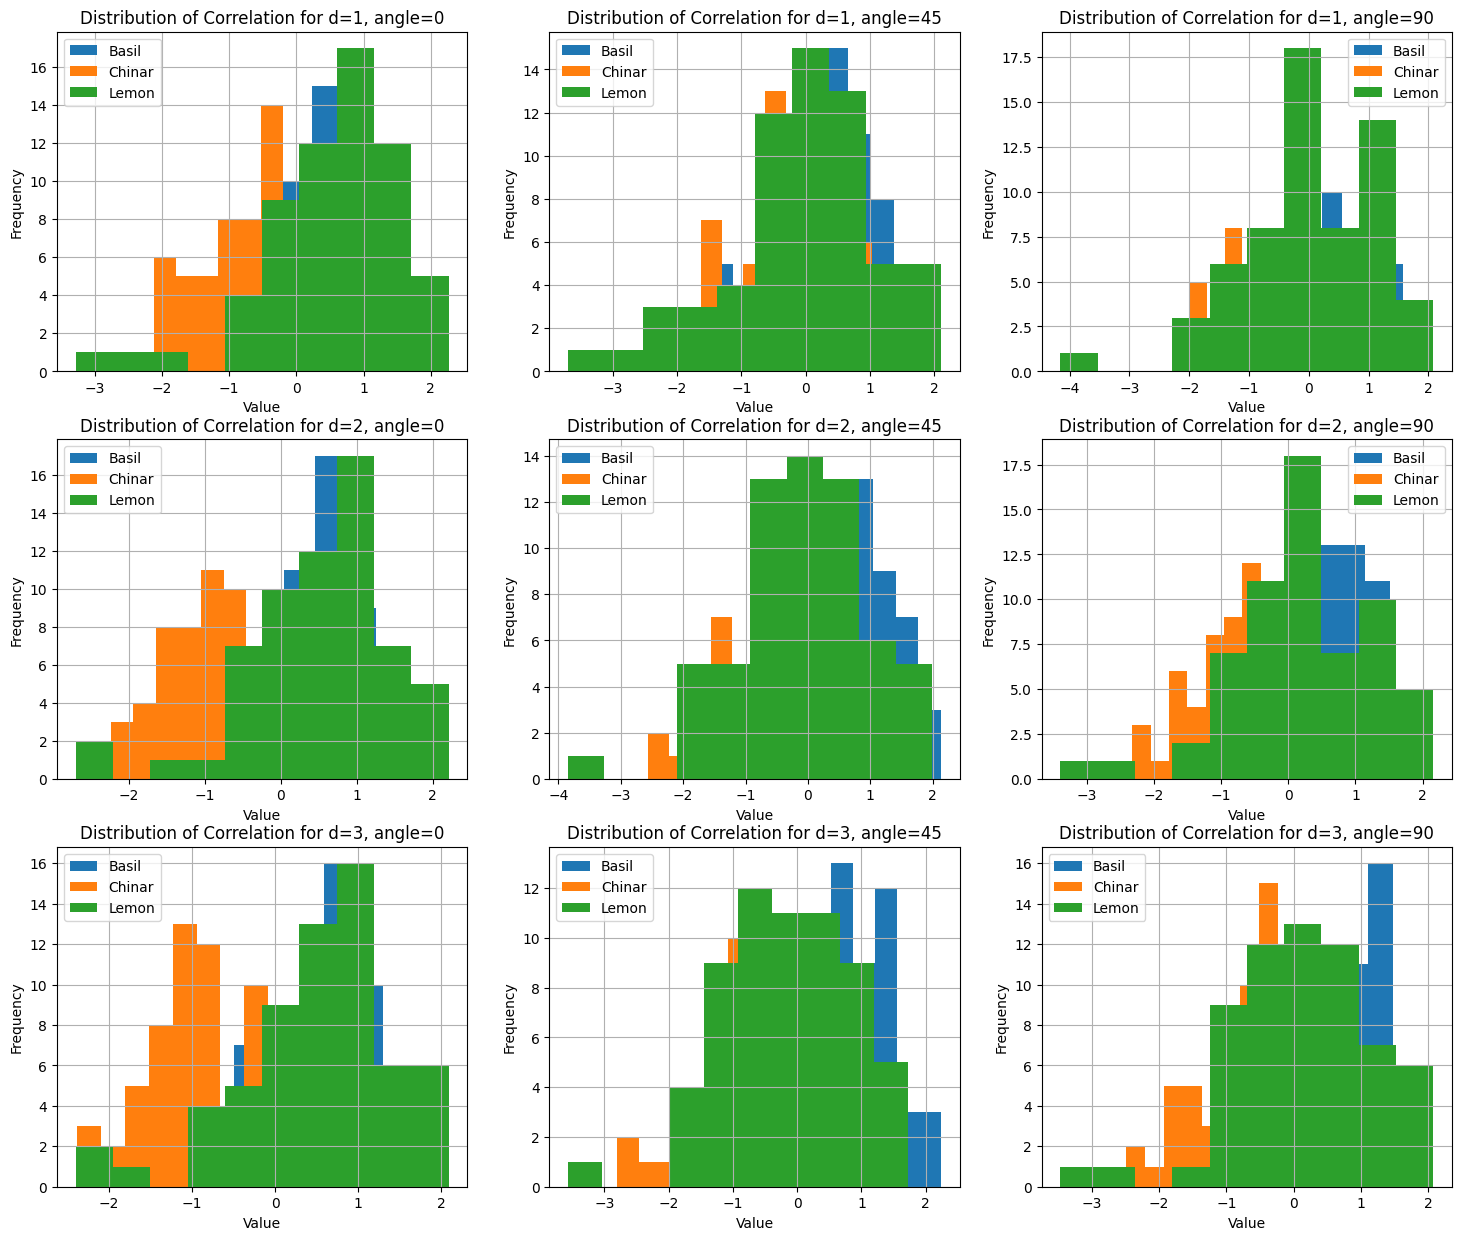

In [146]:
featureNames = ['meanR', 'meanG', 'meanB', 'varR', 'varG', 'varB']
classes = list(featuresDict.keys())   #Classes in dataset
standarizedfeaturesDict = dict()    #A dictionary that contains seperate dictionaries which contains np arrays for each feature
for className in classes:
    standarizedfeaturesDict[className] = dict()

#Here, we standardize all the first order features
for feature in featureNames:
    features = extractFeature(featuresDict, feature)
    #Calculate means and std devs of each feature
    mean = np.mean(features)
    stdDev = np.std(features)
    for className in classes:   #Normalize each value for each class
        featuresClassSpecific = extractFeature(featuresDict, feature, className)
        standardized = (featuresClassSpecific-mean)/stdDev
        standarizedfeaturesDict[className][feature] = standardized

#Standardizing the GLCM features

#Get all correlation feature matrices
allCorrMatrix = list()
for className in classes:
    for imgFeatures in featuresDict[className]: #Iterate through each image
        corrMatrix = imgFeatures["correlation"]
        allCorrMatrix.append(corrMatrix)
allCorrMatrix = np.array(allCorrMatrix)
#Calculate mean and variance for each distance and angle
means = np.mean(allCorrMatrix, axis=0)   
stdDevs  = np.std(allCorrMatrix, axis=0)    

#Normalize the correlation features for each angle and distance
for className in classes:
    temp = list()
    for imgFeatures in featuresDict[className]: #Iterate through each image
        corrMatrix = imgFeatures["correlation"]
        standardized = (corrMatrix-means)/stdDevs
        temp.append(standardized)
    temp = np.array(temp)
    standarizedfeaturesDict[className]["correlation"] = temp
        



#Plots the features
#Create the figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
#Create sub-plots
for idx in range(len(featureNames)):    #Go thru each feature
    feature = featureNames[idx]
    ax = axes[idx]
    for classType, vals in standarizedfeaturesDict.items():   #Go through each class type
        featureList = vals[feature]    #Extract this feature's values as a list
        ax.hist(featureList, bins=30, label=classType)
        ax.set_xlabel('Value')
        ax.set_ylabel('Frequency')
        ax.set_title(f'Distribution of {feature}')
        ax.legend()
        ax.grid()

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for distance in distancesGLCM:
    distIdx = distancesGLCM.index(distance)
    for angle in anglesGLCM:
        angleIdx = anglesGLCM.index(angle)
        for className in classes:
            corrList = list()
            ax = axes[distIdx][angleIdx]
            for corr in standarizedfeaturesDict[className]["correlation"]:
                corrList.append(corr[distIdx][angleIdx])
            ax.hist(corrList,label=className)
            ax.set_xlabel('Value')
            ax.set_ylabel('Frequency')
            ax.set_title(f"Distribution of Correlation for d={distance}, angle={angle}")
            ax.legend()
            ax.grid()



# Build classifiers and select the best hyperparameters with cross validation

Perform model selection using Stratified K-Fold Cross Validation and GridSearchCV.<br>
<br>

**Ridge Classifier (1 p)**

Regularization strength:
alpha = [0.001, 0.01, 0.1, 1.0]<br>
<br>

**Random Forest (1 p)**

n_estimators from 100 to 300 (step size 50)

max_features = ['sqrt', 'log2', None]

Use of bootstrap sampling

Report feature importance for each feature.
Which features are the most important?
Does this match your earlier observations? (1 p)<br>
<br>

**MLP (1 p)**

One hidden layer

Number of neurons: 15–40 (step size 5)

Activation functions: tanh, ReLU

Solvers: SGD, Adam

Validation fraction: 0.1, 0.3

L2 regularization strength: alpha = [0.01, 0.1, 1]<br>
<br>

**For each classifier:**

Report the selected hyperparameters

Report accuracy values for tested combinations

# Estimate the performance of the models with nested cross-validation

Estimate model performance using nested cross-validation.

Inner loop: 5-fold Stratified K-Fold (model selection)

Outer loop: 4-fold Stratified K-Fold (performance estimation)<br>
<br>

For each classifier:

Ridge Classifier **(1 p)**

Random Forest **(1 p)**

MLP **(1 p)**<br>
<br>

Report:

Selected hyperparameters

Accuracy value of the best model

Confusion matrix

Mean accuracy of the outer folds
Explain what this value represents

# Discussion (2 p)

Discuss your results, for example:

Which classifier performed best and why?

What are the limitations of the approach?

How could the results be improved?